In [12]:
from lightgbm import LGBMClassifier
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
train = pd.read_csv('train-2.csv')

main_titles = ['Mr', 'Miss', 'Mrs', 'Master']
train['Sex_coding'] = train['Sex'].map({'male': 1, 'female': 0})
train['family_size'] = train['SibSp'] + train['Parch'] + 1
train['Embarked'] = train['Embarked'].fillna('S')

train['Title'] = train['Name'].str.split(', ').str[1].str.split('.').str[0]
train['Title'] = train['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
train['Title'] = train['Title'].where(train['Title'].isin(main_titles), 'Rare')

train = pd.get_dummies(train, columns=['Embarked', 'Title'], dtype=int)

features_for_predict = ['Pclass', 'Sex_coding','Age','Fare', 'family_size','Embarked_C','Embarked_Q','Embarked_S','Title_Master',	'Title_Miss',	'Title_Mr',	'Title_Mrs',	'Title_Rare']
X,y = train[features_for_predict],train['Survived']

In [13]:

train_value = []
test_value = []
n_estimators = [10, 25, 50, 100, 200, 400, 800]
for i in n_estimators:
    pipeline = make_pipeline(SimpleImputer(strategy='median'), LGBMClassifier(random_state=42, verbose=-1,learning_rate=0.1,max_depth=3, n_estimators=i))
    cross_model= cross_validate(pipeline, X,y,cv = 5, return_train_score=True)
    print(cross_model['train_score'].mean())
    print(cross_model['test_score'].mean())
    print(i)
    train_value.append(cross_model['train_score'].mean())
    test_value.append(cross_model['test_score'].mean())
    print()




0.8310879808374174
0.8237649865042999
10

0.8538175457396348
0.8192831586215557
25

0.8627940967899523
0.8215491808423827
50

0.8858010148604567
0.8327663046889713
100

0.9048796823045526
0.8339024543343168
200

0.9276084592716328
0.839539263071998
400

0.9528605985155302
0.8294269035214361
800



In [14]:
train_value_new = []
test_value_new = []
for p in [0.3, 0.1, 0.03, 0.01]:
    for q in [50, 200, 800]:
        pipeline = make_pipeline(SimpleImputer(strategy='median'), LGBMClassifier(random_state=42, verbose=-1,learning_rate=p,max_depth=3, n_estimators=q))
        cross_model= cross_validate(pipeline, X,y,cv = 5, return_train_score=True)
        print(cross_model['train_score'].mean())
        print(cross_model['test_score'].mean())
        print(f'Learning rate: {p}')
        print(f'N_estimators: {q}')

        train_value_new.append(cross_model['train_score'].mean())
        test_value_new.append(cross_model['test_score'].mean())
        print()


0.9001126747246166
0.8294143493817085
Learning rate: 0.3
N_estimators: 50

0.94837133807145
0.824938798568828
Learning rate: 0.3
N_estimators: 200

0.9783932426682636
0.8047454648170234
Learning rate: 0.3
N_estimators: 800

0.8627940967899523
0.8215491808423827
Learning rate: 0.1
N_estimators: 50

0.9048796823045526
0.8339024543343168
Learning rate: 0.1
N_estimators: 200

0.9528605985155302
0.8294269035214361
Learning rate: 0.1
N_estimators: 800

0.8358573522227651
0.821517795493064
Learning rate: 0.03
N_estimators: 50

0.8714925067368455
0.8260498399347185
Learning rate: 0.03
N_estimators: 200

0.9104933261893879
0.8383968363567889
Learning rate: 0.03
N_estimators: 800

0.8016282679609814
0.7957692549118073
Learning rate: 0.01
N_estimators: 50

0.8425902579699638
0.8215052413533362
Learning rate: 0.01
N_estimators: 200

0.8793482200545251
0.8305316678174629
Learning rate: 0.01
N_estimators: 800



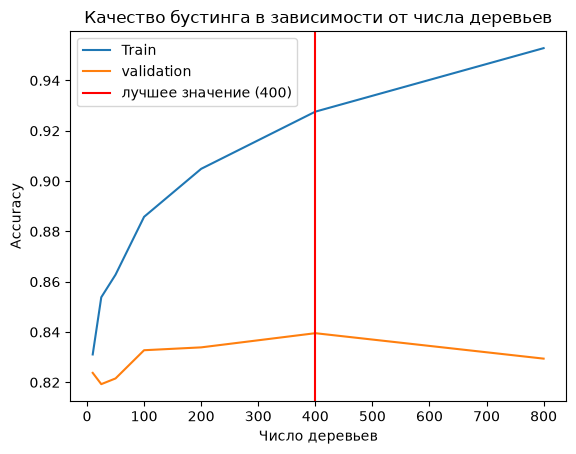

In [15]:

fig,ax = plt.subplots()
ax.plot(n_estimators,np.array(train_value),label = 'Train')
ax.plot(n_estimators,np.array(test_value),label = 'validation')
ax.set_title('Качество бустинга в зависимости от числа деревьев')
ax.set_xlabel('Число деревьев')
ax.axvline(400,label = 'лучшее значение (400)',color = 'red')
ax.set_ylabel('Accuracy')
ax.legend()
plt.show()

## Вывод: градиентный бустинг (LightGBM) на Titanic, 13 признаков, CV 5 фолдов

**1. Число деревьев** (`learning_rate = 0.1`, `max_depth = 3`):

| n_estimators | Train | Validation | Разрыв |
|---|---|---|---|
| 10 | 0.831 | 0.824 | 0.007 |
| 25 | 0.854 | 0.819 | 0.035 |
| 50 | 0.863 | 0.822 | 0.041 |
| 100 | 0.886 | 0.833 | 0.053 |
| 200 | 0.905 | 0.834 | 0.071 |
| 400 | 0.928 | 0.840 | 0.088 |
| 800 | 0.953 | 0.829 | 0.123 |

Для параметра n_estimators лучшее значение 400 (validation 0.840). При росте числа деревьев качество на train продолжает расти, а на validation после 400 немного снижается, поэтому разрыв увеличивается: это переобучение. При малом числе деревьев (10–50) модель ещё недообучена.

**2. Связка learning_rate и n_estimators** (validation):

| learning_rate | n = 50 | n = 200 | n = 800 |
|---|---|---|---|
| 0.3 | 0.829 | 0.825 | 0.805 |
| 0.1 | 0.822 | 0.834 | 0.829 |
| 0.03 | 0.822 | 0.826 | 0.838 |
| 0.01 | 0.796 | 0.822 | 0.831 |

Для связки learning_rate и n_estimators наилучшими значениями стали learning_rate = 0.03 и n_estimators = 800 (validation 0.838). Чем меньше learning_rate, тем больше деревьев нужно для лучшего качества: при 0.3 лучший результат уже при 50 деревьях, а при 800 модель переобучается (0.805), при 0.03 лучший результат при 800, а при 0.01 качество на 800 деревьях ещё растёт.

**3. Сравнение с другими моделями** (CV-accuracy):

| Модель | CV accuracy |
|---|---|
| Логистическая регрессия | 0.827 |
| Случайный лес (max_depth = 4) | 0.831 |
| Бустинг (лучшие параметры) | 0.838–0.840 |

Значение бустинга чуть лучше логистической регрессии, но практически равно случайному лесу: разница около 0.01 лежит в пределах шума, к тому же параметры бустинга выбирались перебором по тем же фолдам, поэтому оценка немного завышена.